# Pakistan House Price Predictor: Model Training

**Notebook 03.** Uses the cleaned data from notebook 01 to train and compare models that predict a house's sale price.

Plan:
1. Choose the features and the target
2. Split the data into a training set and a test set
3. Turn categories (city, property type, location) into numbers
4. Train four models, from simplest to strongest, and compare them
5. Look at the errors and which features matter most
6. Save the best model for the web app

## 1. Setup

In [15]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
os.makedirs("../images", exist_ok=True)
os.makedirs("../models", exist_ok=True)

In [16]:
df = pd.read_csv("../data/cleaned_house_prices.csv")
print(df.shape)
df.head()

(80351, 16)


,location_id,property_type,price,location,city,province_name,latitude,longitude,baths,bedrooms,date_added,area_marla,year_added,month_added,bedrooms_was_missing,baths_was_missing
0,3325,Flat,10000000,G-10,Islamabad,Islamabad Capital,33.679890,73.012640,2,2,2019-02-04,4.0,2019,2,False,False
1,3236,Flat,6900000,E-11,Islamabad,Islamabad Capital,33.700993,72.971492,3,3,2019-05-04,5.6,2019,5,False,False
2,764,House,16500000,G-15,Islamabad,Islamabad Capital,33.631486,72.926559,6,5,2019-07-17,8.0,2019,7,False,False
3,340,House,43500000,Bani Gala,Islamabad,Islamabad Capital,33.707573,73.151199,4,4,2019-04-05,40.0,2019,4,False,False
4,3226,House,7000000,DHA Defence,Islamabad,Islamabad Capital,33.492591,73.301339,3,3,2019-07-10,8.0,2019,7,False,False


## 2. Choose the features and the target

**Target:** `price`.

**Features:** only things a person can actually type into a website: property type, city, location, area, bedrooms and baths.

I leave out on purpose:
- `year_added`, `month_added`: a user does not know them, and they had almost no correlation with price
- `bedrooms_was_missing`, `baths_was_missing`: these describe how the data was filled, not the house
- `latitude`, `longitude`: users will not know them (a possible improvement later)
- `location_id`: an ID number with no meaning as a number

Two new features:
- `city_location`: the same location name can exist in two cities (for example "DHA Phase 5"), so I join city and location
- `log_area`: price grows more like a percentage than a fixed amount, so the logarithm of the area helps simple models

In [17]:
df["city_location"] = df["city"] + " | " + df["location"]
df["log_area"] = np.log1p(df["area_marla"])

features = ["area_marla", "log_area", "bedrooms", "baths",
            "property_type", "city", "city_location"]

X = df[features]
y = df["price"]

print("Different locations:", df["city_location"].nunique())
X.head()

Different locations: 1518


,area_marla,log_area,bedrooms,baths,property_type,city,city_location
0,4.0,1.609438,2,2,Flat,Islamabad,Islamabad | G-10
1,5.6,1.887070,3,3,Flat,Islamabad,Islamabad | E-11
2,8.0,2.197225,5,6,House,Islamabad,Islamabad | G-15
3,40.0,3.713572,4,4,House,Islamabad,Islamabad | Bani Gala
4,8.0,2.197225,3,3,House,Islamabad,Islamabad | DHA Defence


## 3. Predict the log of the price

In the EDA, prices were very skewed: a few very expensive houses and many cheaper ones. If the model learns the raw price, those few big values dominate the training. The fix is to train on `log(price)` and convert the answer back at the end with `exp`. Errors then behave like percentages ("5% too high") instead of fixed amounts.

## 4. Train and test split

I hide 20% of the houses (the **test set**) and train only on the other 80%. Then I measure the model on houses it has never seen. Measuring on training data would be like marking a student's exam using questions they have already seen.

`random_state=42` makes the split the same every time I run it.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# The models learn from the log of the price
y_train_log = np.log1p(y_train)

print("Training houses:", len(X_train))
print("Test houses:", len(X_test))

Training houses: 64280
Test houses: 16071


## 5. Turn categories into numbers

Models only understand numbers. **One-hot encoding** turns a column like `city` into one yes/no column per city (`city_Lahore` = 1 or 0).

- `property_type` and `city` have few values, so every value gets a column
- `city_location` has many values. Locations with fewer than 30 listings are grouped into one "rare location" column, because a model cannot learn from 3 houses
- A location the model has never seen is handled safely instead of crashing
- The number columns (area, bedrooms, baths) pass through unchanged

In [19]:
preprocess = ColumnTransformer(
    transformers=[
        ("small_categories",
         OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         ["property_type", "city"]),
        ("location",
         OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False),
         ["city_location"]),
    ],
    remainder="passthrough",   # area_marla, log_area, bedrooms, baths
)

## 6. How I measure the models

All errors are calculated on the **test set**, in the real price (crore PKR).

| Metric | Meaning | Better is |
|---|---|---|
| **MAE** | Average mistake in crore PKR | lower |
| **RMSE** | Like MAE but punishes big mistakes more | lower |
| **R² (price)** | Share of the price variation the model explains (1.0 is perfect) | higher |
| **R² (log price)** | Same, but on the log scale where most data lives | higher |
| **Median % error** | In a typical case, how far off is the prediction in percent | lower |

I use the **median % error** as the main number, because it is easy to explain: "a typical prediction is off by about X%".

In [20]:
def evaluate(name, pipe):
    pred_log = pipe.predict(X_test)          # the model predicts the log price
    pred = np.expm1(pred_log)                # convert back to PKR
    return {
        "Model": name,
        "MAE (crore)": mean_absolute_error(y_test, pred) / 1e7,
        "RMSE (crore)": np.sqrt(mean_squared_error(y_test, pred)) / 1e7,
        "R2 (price)": r2_score(y_test, pred),
        "R2 (log price)": r2_score(np.log1p(y_test), pred_log),
        "Median % error": np.median(np.abs(pred - y_test) / y_test) * 100,
    }

## 7. Train four models

1. **Dummy baseline:** always predicts the typical price. Any real model must beat this, otherwise it has learned nothing.
2. **Linear Regression:** draws the best straight-line relationship. Simple and easy to explain.
3. **Random Forest:** many decision trees that vote together. Handles curves and interactions.
4. **Gradient Boosting:** trees that fix each other's mistakes one after another. Usually the strongest on tables like this.

Random Forest may take a few minutes.

In [21]:
models = {
    "Dummy baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=2,
                                           max_features=0.33, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08,
                                                       random_state=42),
}

fitted = {}
rows = []
for name, model in models.items():
    start = time.time()
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train_log)
    fitted[name] = pipe
    row = evaluate(name, pipe)
    row["Seconds"] = time.time() - start
    rows.append(row)
    print(f"{name}: done in {row['Seconds']:.0f}s")

results = pd.DataFrame(rows).set_index("Model").sort_values("Median % error")
results.round(3)

Dummy baseline: done in 0s
Linear Regression: done in 2s
Random Forest: done in 26s
Gradient Boosting: done in 20s


,MAE (crore),RMSE (crore),R2 (price),R2 (log price),Median % error,Seconds
Model,,,,,,
Random Forest,0.480,1.005,0.864,0.889,15.220,26.409
Gradient Boosting,0.475,0.988,0.868,0.896,15.404,20.389
Linear Regression,0.547,1.137,0.826,0.865,18.413,1.774
Dummy baseline,1.557,2.884,-0.121,-0.004,60.000,0.290


### My conclusion

Random Forest and Gradient Boosting are almost tied, and both are clearly better than Linear Regression and the dummy baseline.

- **Gradient Boosting** is better on 4 of the 5 metrics: MAE 0.475 crore, RMSE 0.988 crore, R2 (price) 0.868 and R2 (log price) 0.896.
- **Random Forest** has the lowest median % error (15.22% vs 15.40%), so the rule in my code selected it automatically as the "best" model. The gap is only 0.18 percentage points, which is too small to matter.
- **Linear Regression** is worse (18.4% median error), and the **dummy baseline** is far behind (60% error, negative R2), so the real models learned real patterns.

In practice, a typical prediction is off by about 15%.

Which model to deploy will depend on size and speed: the saved Random Forest file is 147.6 MB, so I will compare it with Gradient Boosting before deploying.

## 8. Look at the best model's errors

Numbers hide patterns, so I plot them. In the first chart, a perfect model would put every dot on the diagonal line. The second chart shows how big the percentage errors are.

Best model: Random Forest


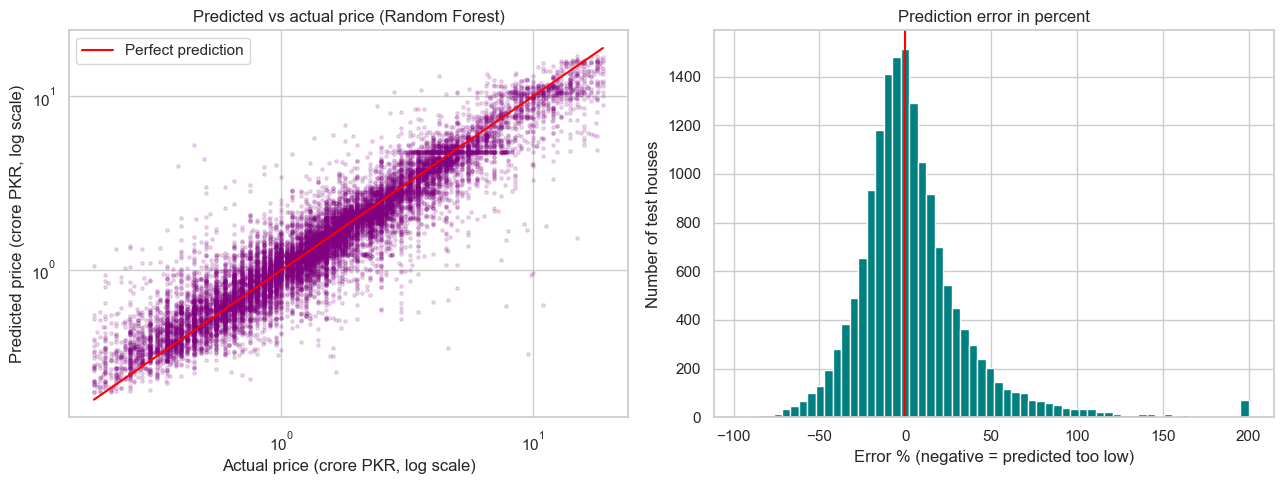

In [22]:
best_name = results.index[0]
best_pipe = fitted[best_name]
print("Best model:", best_name)

pred = np.expm1(best_pipe.predict(X_test))
actual = y_test.values
pct_error = (pred - actual) / actual * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: predicted vs actual price
axes[0].scatter(actual / 1e7, pred / 1e7, alpha=0.15, s=6, color="purple")
low, high = actual.min() / 1e7, actual.max() / 1e7
axes[0].plot([low, high], [low, high], color="red", linewidth=1.5, label="Perfect prediction")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title(f"Predicted vs actual price ({best_name})")
axes[0].set_xlabel("Actual price (crore PKR, log scale)")
axes[0].set_ylabel("Predicted price (crore PKR, log scale)")
axes[0].legend()

# Right: how far off are the predictions, in percent
axes[1].hist(pct_error.clip(-100, 200), bins=60, color="teal", edgecolor="white")
axes[1].axvline(0, color="red", linewidth=1.5)
axes[1].set_title("Prediction error in percent")
axes[1].set_xlabel("Error % (negative = predicted too low)")
axes[1].set_ylabel("Number of test houses")

plt.tight_layout()
plt.savefig("../images/08_model_errors.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows:** The dots follow the red line (a perfect prediction), so the model gets the price level right from cheap to expensive houses. The error chart is centred near 0, so the model is not usually too high or too low. But the spread is wide: a typical error is about 15%, and some houses are over-predicted by 100% or more (the last bar at 200% includes everything above 200%). For houses above about 10 crore the dots fall below the line, so the model under-predicts very expensive houses.

## 9. Where is the model wrong?

An average hides weak spots. I check the error for each city and each property type.

In [23]:
errors = X_test.copy()
errors["abs_pct_error"] = np.abs(pct_error)

print("Median % error by city")
print(errors.groupby("city")["abs_pct_error"].median().round(1).sort_values())

Median % error by city
city
Islamabad     13.2
Lahore        13.9
Rawalpindi    15.3
Karachi       17.2
Faisalabad    17.9
Name: abs_pct_error, dtype: float64


In [24]:
print("Median % error by property type (with number of test houses)")
by_type = errors.groupby("property_type")["abs_pct_error"].agg(["median", "count"])
by_type["median"] = by_type["median"].round(1)
by_type.sort_values("median")

Median % error by property type (with number of test houses)


,median,count
property_type,,
Room,14.0,2
Upper Portion,14.4,390
House,14.5,11627
Lower Portion,14.9,167
Flat,17.5,3785
Farm House,31.8,40
Penthouse,32.6,60


**What it shows:** Islamabad (13.2%) and Lahore (13.9%) are the easiest cities to predict. Faisalabad (17.9%) and Karachi (17.2%) are the hardest. By property type, Penthouse (32.6%) and Farm House (31.8%) have by far the biggest errors, but they have only 60 and 40 test houses, so these numbers are less reliable. The model has few examples of these rare types to learn from. Flats (17.5%) are the hardest of the common types, while Houses (14.5%) are among the easiest and have the most examples (11,627). Room (14.0%) has only 2 test houses, so I ignore it.

## 10. Which features matter most?

**Permutation importance:** shuffle one feature's values randomly and see how much worse the model gets. If shuffling `area_marla` ruins the predictions, that feature matters a lot. If shuffling `baths` changes almost nothing, it matters little.

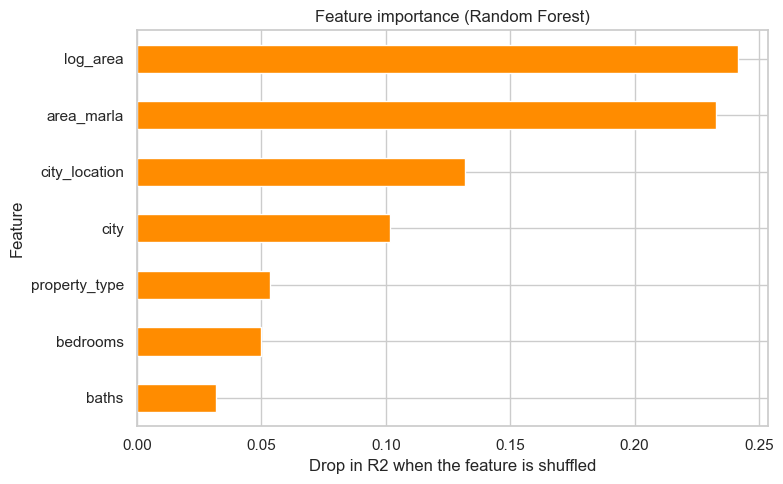

log_area         0.241
area_marla       0.233
city_location    0.132
city             0.101
property_type    0.053
bedrooms         0.050
baths            0.032
dtype: float64

In [25]:
sample = X_test.sample(min(5000, len(X_test)), random_state=42)

imp = permutation_importance(best_pipe, sample, np.log1p(y_test.loc[sample.index]),
                             n_repeats=3, random_state=42, scoring="r2", n_jobs=-1)

importance = (pd.Series(imp.importances_mean, index=sample.columns)
                .sort_values())

fig, ax = plt.subplots(figsize=(8, 5))
importance.plot(kind="barh", ax=ax, color="darkorange")
ax.set_title(f"Feature importance ({best_name})")
ax.set_xlabel("Drop in R2 when the feature is shuffled")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.savefig("../images/09_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance.sort_values(ascending=False).round(3)

**What it shows:** Area is the most important feature. `log_area` (0.241) and `area_marla` (0.233) are the same information in two forms, so together they are the main driver, which matches the EDA (price and area had a correlation of 0.84). Location comes next: `city_location` (0.132) and `city` (0.101). Property type (0.053), bedrooms (0.050) and baths (0.032) matter least, probably because they overlap with area (bigger houses have more bedrooms and baths).

## 11. Predict a price for one house

A small function that takes a house's details and returns a price. The API in the next step will use exactly the same idea.

In [26]:
def predict_price(property_type, city, location, area_marla, bedrooms, baths, model=best_pipe):
    house = pd.DataFrame([{
        "area_marla": area_marla,
        "log_area": np.log1p(area_marla),
        "bedrooms": bedrooms,
        "baths": baths,
        "property_type": property_type,
        "city": city,
        "city_location": f"{city} | {location}",
    }])
    price = np.expm1(model.predict(house)[0])
    return price / 1e7      # crore PKR

# Try a real row from the data
row = df.iloc[0]
estimate = predict_price(row["property_type"], row["city"], row["location"],
                         row["area_marla"], row["bedrooms"], row["baths"])
print(f"{row['property_type']} in {row['location']}, {row['city']}, {row['area_marla']} marla")
print(f"Predicted: {estimate:.2f} crore | Actual: {row['price'] / 1e7:.2f} crore")

Flat in G-10, Islamabad, 4.0 marla
Predicted: 0.71 crore | Actual: 1.00 crore


In [27]:
# Change these values and run the cell to try your own house
predict_price(property_type="House", city="Lahore", location="DHA Defence",
              area_marla=10, bedrooms=4, baths=4)

np.float64(2.7522717158252887)

*Note: the location name must exist in the data. If you type a location that is not in the dataset, the model treats it as a rare location and the estimate is less reliable.*

## 12. Save the best model

The saved file contains the whole pipeline (encoding and model), so the API can load it and predict from raw input. Model files can be large, so they are not committed to Git.

In [28]:
joblib.dump(best_pipe, "../models/house_price_model.joblib")

metrics = results.round(4).reset_index().to_dict(orient="records")
with open("../models/metrics.json", "w") as f:
    json.dump({"best_model": best_name, "features": features, "results": metrics}, f, indent=2)

size_mb = os.path.getsize("../models/house_price_model.joblib") / 1024 / 1024
print(f"Saved {best_name} ({size_mb:.1f} MB)")

Saved Random Forest (147.6 MB)


## Limitations and next experiments

- **The test set is a random split.** Some similar houses (the same project or society) may appear in both sets, so the real-world error could be a little higher.
- **Very expensive houses:** the model under-predicts houses above about 10 crore, and rare types such as Penthouse and Farm House have errors above 30%.
- **Duplicate rule:** I removed duplicates with a strict rule. Next, I will compare it with a milder rule.
- **Time:** the data covers a short period (2018 to 2019), so prices today are different. The model needs fresh data to stay accurate.
- **Next experiments:** add `latitude` and `longitude`, tune the model settings, use cross-validation, and try XGBoost.

## What I learned in this notebook

1. I trained 3 real models and a dummy baseline. The dummy shows what "no learning" scores (60% error), so I know the real models learned something (about 15% error).
2. I used 80% of the houses for training and 20% for testing, so the scores come from houses the model has never seen.
3. The best model depends on the metric: Random Forest has the lowest median % error, while Gradient Boosting wins the other four. I need to look at more than one number before choosing.
4. Averages hide weak spots. The error by city and by property type showed that rare types are much harder to predict.